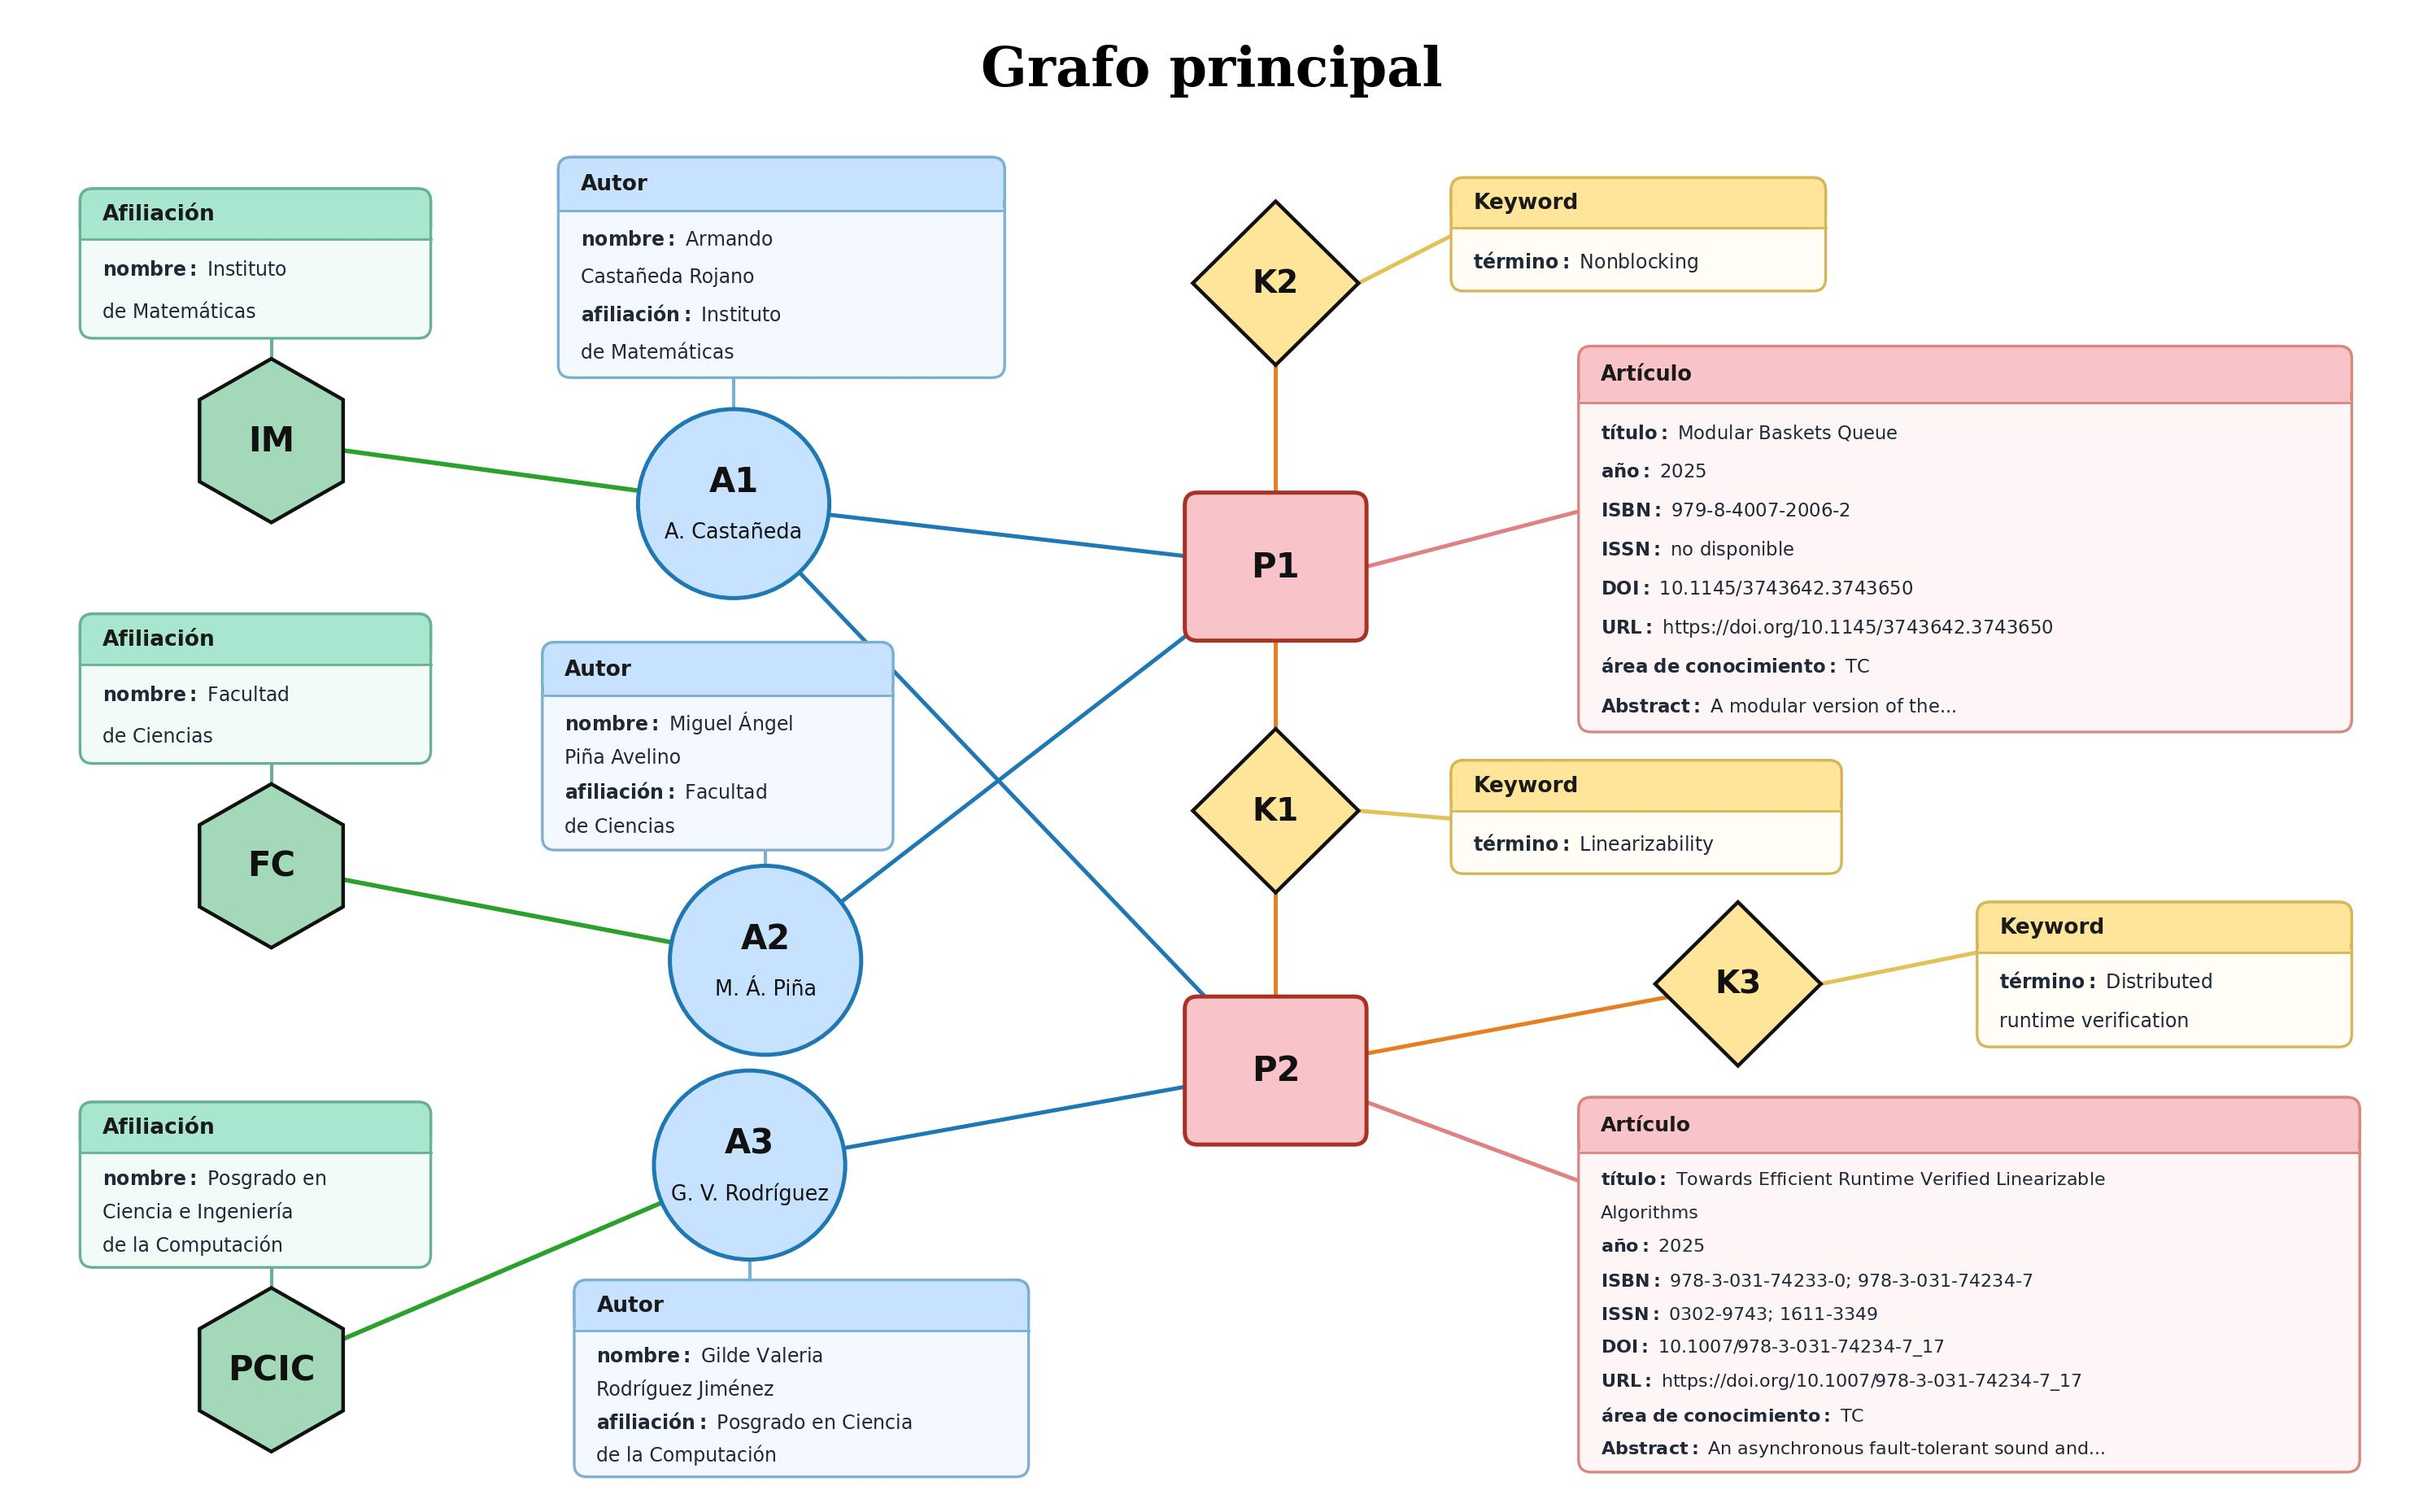

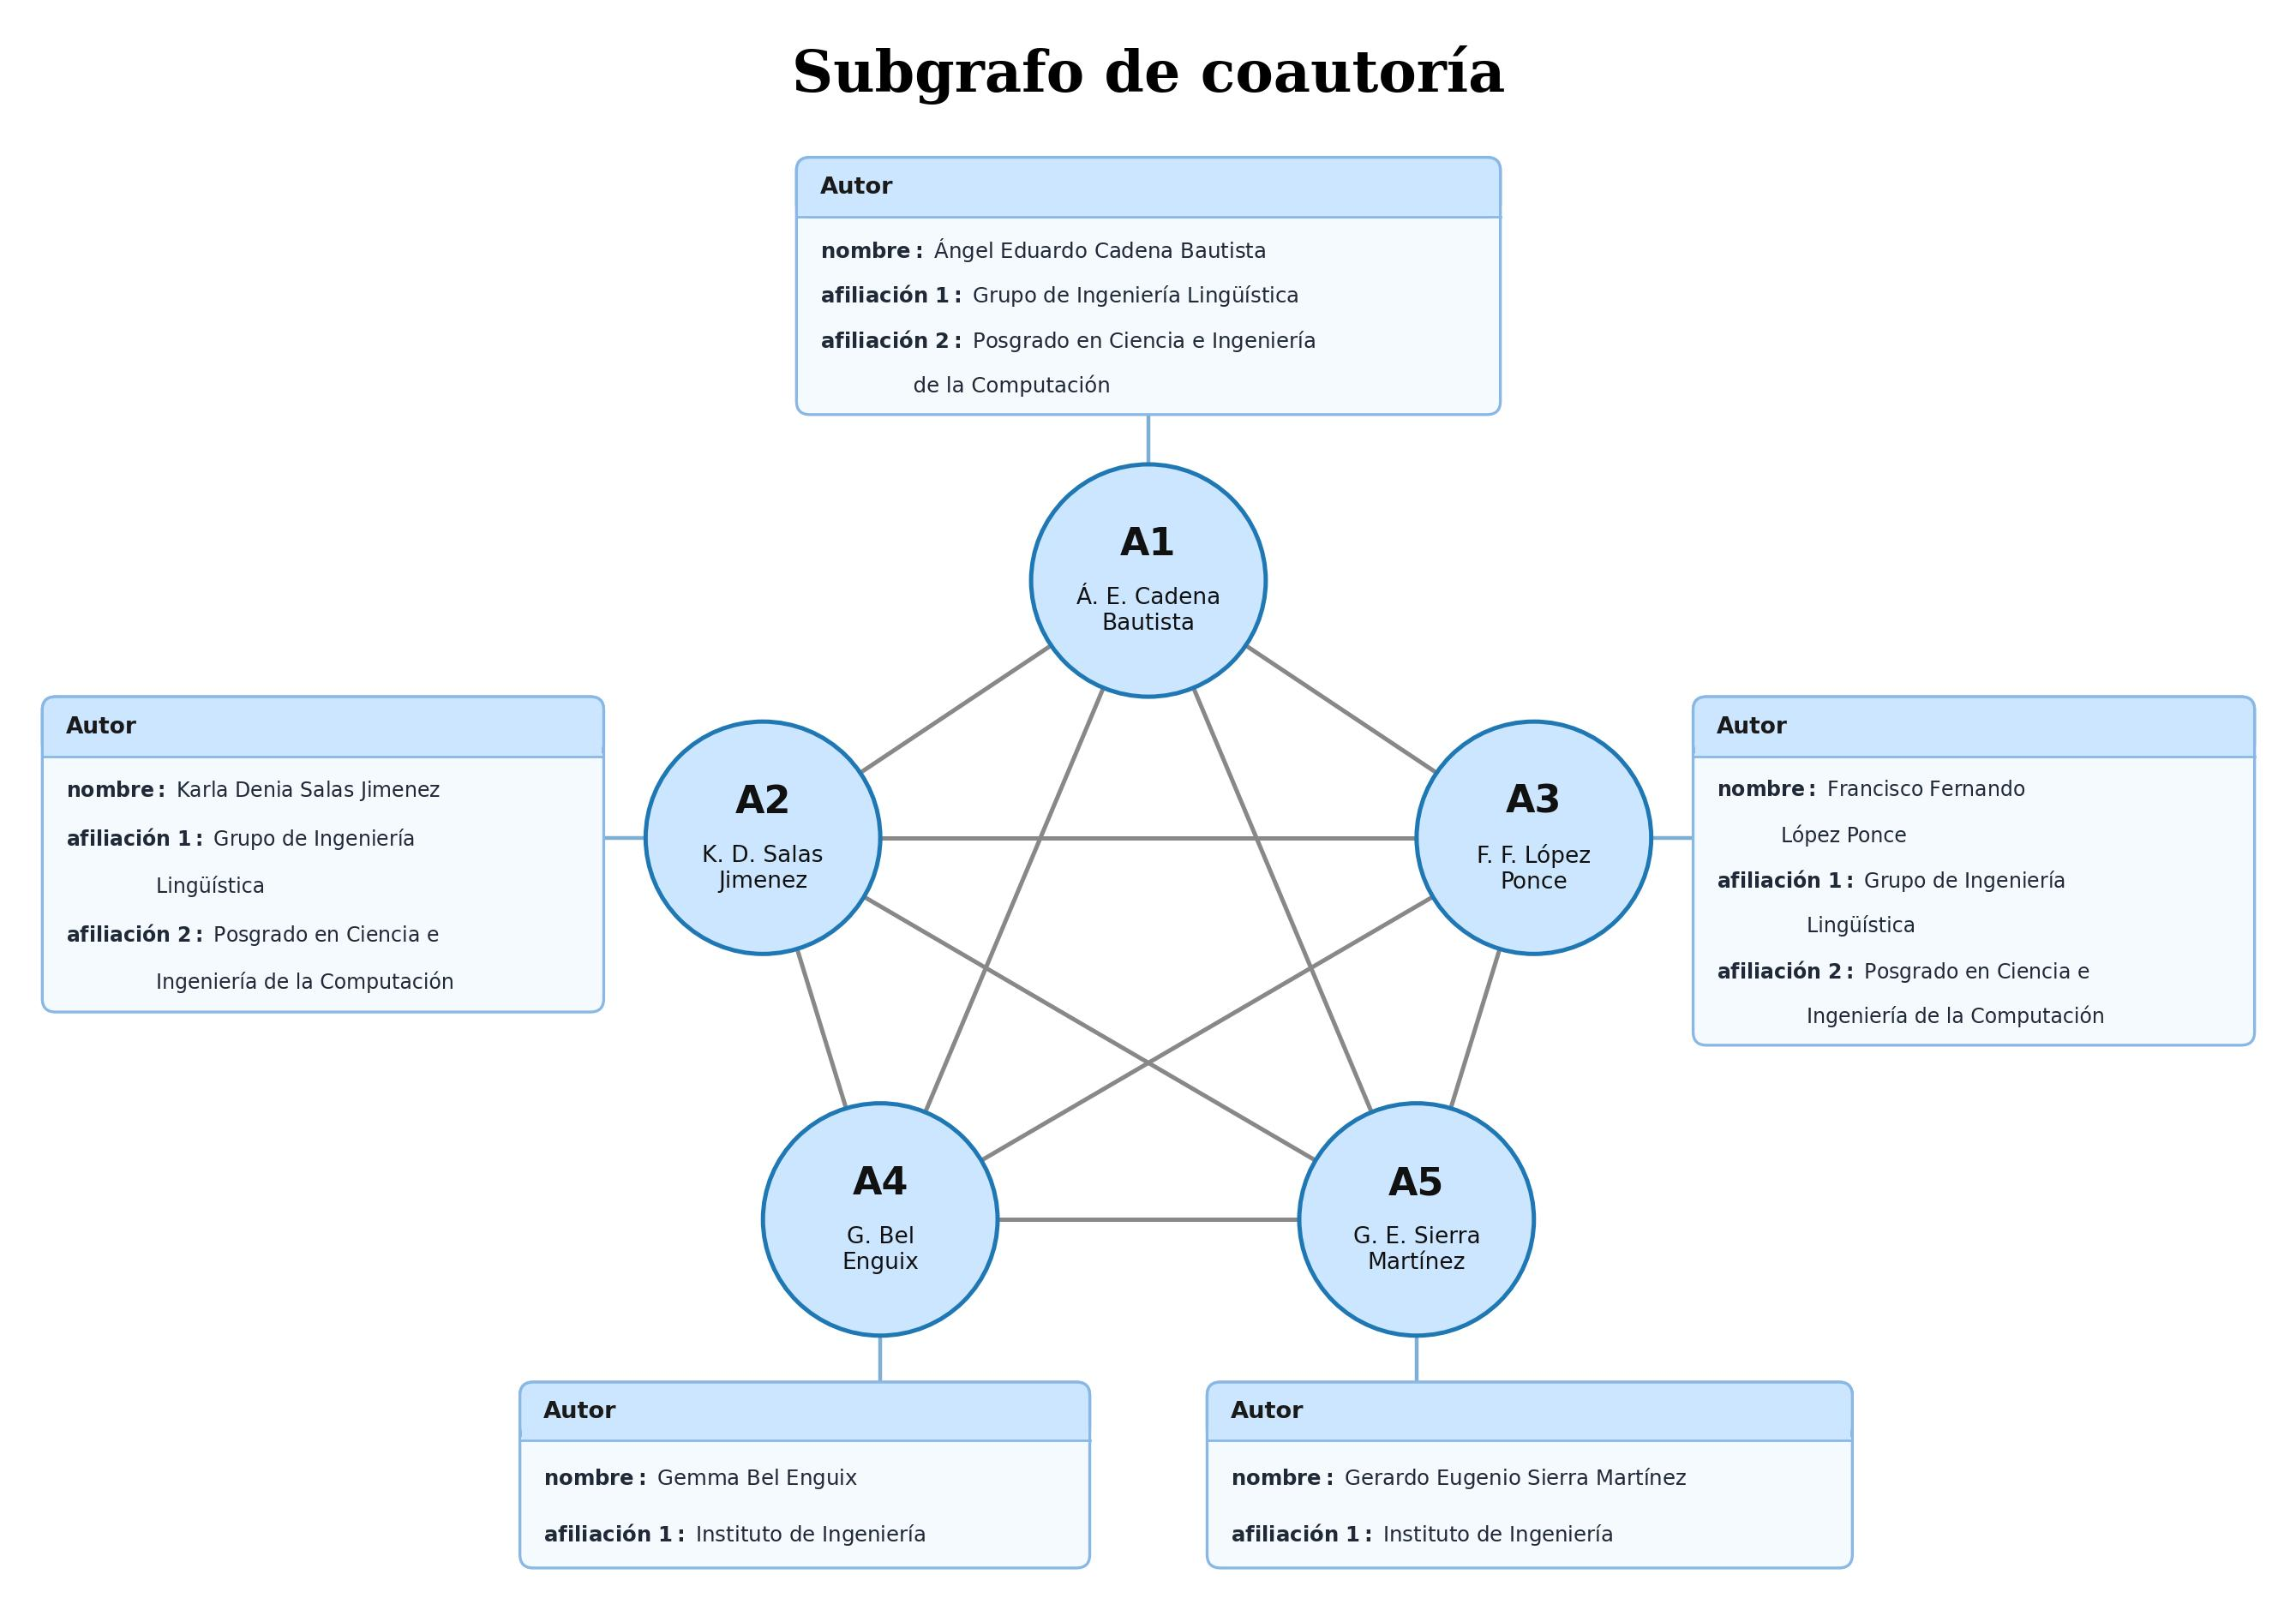

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

def draw_info_card(ax, x, y, w, h, header_text, lines, header_bg, body_bg, border_color, header_h=0.36, fontsize=8.5, radius=0.08):
    """Dibuja una tarjeta informativa con encabezado de color y bordes redondeados."""
    # Cuerpo principal de la tarjeta
    body = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle=f"round,pad=0,rounding_size={radius}",
        facecolor=body_bg, edgecolor=border_color, linewidth=1.2, zorder=3
    )
    ax.add_patch(body)
    
    # Encabezado superior
    header = patches.FancyBboxPatch(
        (x, y + h - header_h), w, header_h,
        boxstyle=f"round,pad=0,rounding_size={radius}",
        facecolor=header_bg, edgecolor=border_color, linewidth=1.2, zorder=4
    )
    ax.add_patch(header)
    
    # Cubrir las esquinas inferiores del encabezado para que la línea divisoria sea recta
    rect_cover = patches.Rectangle(
        (x + 0.01, y + h - header_h), w - 0.02, radius,
        facecolor=header_bg, edgecolor='none', zorder=4.1
    )
    ax.add_patch(rect_cover)
    
    # Línea divisoria
    ax.plot([x, x + w], [y + h - header_h, y + h - header_h], color=border_color, lw=1.0, zorder=4.2)
    
    # Texto del encabezado
    ax.text(x + 0.14, y + h - header_h / 2, header_text,
            fontsize=fontsize + 1, fontweight='bold', va='center', ha='left', color='#1a1a1a', zorder=5)
    
    # Texto del cuerpo: lista de tuplas (etiqueta_negrita, texto_normal)
    line_area = h - header_h - 0.10
    n_lines = len(lines)
    step = line_area / max(n_lines, 1)
    start_y = y + h - header_h - 0.06 - step / 2
    
    for i, (b_txt, r_txt) in enumerate(lines):
        ly = start_y - i * step
        if b_txt:
            b_clean = b_txt.replace(":", "{:}").replace(" ", r"\ ")
            t_full = f"$\\mathbf{{{b_clean}}}$ {r_txt}"
            ax.text(x + 0.14, ly, t_full, fontsize=fontsize, va='center', ha='left', color='#1f2937', zorder=5)
        else:
            ax.text(x + 0.14, ly, r_txt, fontsize=fontsize, va='center', ha='left', color='#1f2937', zorder=5)


# ==============================================================================
# 1. GENERAR IMAGEN 1: GRAFO PRINCIPAL
# ==============================================================================
def generar_grafo_principal(nombre_archivo="grafo_principal.jpg"):
    fig, ax = plt.subplots(figsize=(15, 9.4), dpi=200)
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 9.4)
    ax.axis('off')
    fig.patch.set_facecolor('white')

    # Título
    ax.text(7.5, 9.05, "Grafo principal", fontsize=24, fontweight='bold', family='serif', ha='center', va='center')

    # Posiciones de los nodos
    pos = {
        'IM': (1.6, 6.7),
        'FC': (1.6, 4.0),
        'PCIC': (1.6, 0.8),
        'A1': (4.5, 6.3),
        'A2': (4.7, 3.4),
        'A3': (4.6, 2.1),
        'P1': (7.9, 5.9),
        'P2': (7.9, 2.7),
        'K2': (7.9, 7.7),
        'K1': (7.9, 4.35),
        'K3': (10.8, 3.25),
    }

    # Aristas por tipo de relación
    edges_green = [('IM', 'A1'), ('FC', 'A2'), ('PCIC', 'A3')]
    edges_blue = [('A1', 'P1'), ('A1', 'P2'), ('A2', 'P1'), ('A3', 'P2')]
    edges_orange = [('P1', 'K2'), ('P1', 'K1'), ('P2', 'K1'), ('P2', 'K3')]

    for u, v in edges_green:
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color='#2ca02c', lw=2.0, zorder=1)
    for u, v in edges_blue:
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color='#1f77b4', lw=1.8, zorder=1)
    for u, v in edges_orange:
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color='#e67e22', lw=1.8, zorder=1)

    # Nodos de Afiliación (Hexágonos verdes)
    for node in ['IM', 'FC', 'PCIC']:
        nx, ny = pos[node]
        hexagon = patches.RegularPolygon((nx, ny), numVertices=6, radius=0.52, orientation=0,
                                         facecolor='#a3d9b8', edgecolor='#111111', lw=1.6, zorder=3)
        ax.add_patch(hexagon)
        ax.text(nx, ny, node, fontsize=15, fontweight='bold', ha='center', va='center', color='#111111', zorder=4)

    # Nodos de Autor (Círculos azules)
    authors_labels = {
        'A1': ('A1', 'A. Castañeda'),
        'A2': ('A2', 'M. Á. Piña'),
        'A3': ('A3', 'G. V. Rodríguez'),
    }
    for node, (code, name) in authors_labels.items():
        nx, ny = pos[node]
        circle = patches.Circle((nx, ny), radius=0.60, facecolor='#c6e2ff', edgecolor='#1f77b4', lw=1.8, zorder=3)
        ax.add_patch(circle)
        ax.text(nx, ny + 0.14, code, fontsize=15, fontweight='bold', ha='center', va='center', color='#111111', zorder=4)
        ax.text(nx, ny - 0.18, name, fontsize=9.2, ha='center', va='center', color='#111111', zorder=4)

    # Nodos de Artículo (Cuadrados redondeados rosas)
    for node in ['P1', 'P2']:
        nx, ny = pos[node]
        rect = patches.FancyBboxPatch((nx - 0.52, ny - 0.42), 1.04, 0.84,
                                      boxstyle="round,pad=0.05,rounding_size=0.08",
                                      facecolor='#f9c4c9', edgecolor='#a93226', lw=1.8, zorder=3)
        ax.add_patch(rect)
        ax.text(nx, ny, node, fontsize=15, fontweight='bold', ha='center', va='center', color='#111111', zorder=4)

    # Nodos de Keyword (Rombos amarillos)
    for node in ['K2', 'K1', 'K3']:
        nx, ny = pos[node]
        diamond = patches.RegularPolygon((nx, ny), numVertices=4, radius=0.52, orientation=0,
                                         facecolor='#ffe599', edgecolor='#111111', lw=1.6, zorder=3)
        ax.add_patch(diamond)
        ax.text(nx, ny, node, fontsize=14, fontweight='bold', ha='center', va='center', color='#111111', zorder=4)

    # Tarjetas de Afiliación
    draw_info_card(ax, 0.4, 7.35, 2.2, 0.95, "Afiliación",
                   [("nombre:", "Instituto"), ("", "de Matemáticas")],
                   '#a8e6cf', '#f2fbf7', '#66b293', header_h=0.32)
    ax.plot([1.6, 1.6], [7.22, 7.35], color='#66b293', lw=1.5, zorder=2)

    draw_info_card(ax, 0.4, 4.65, 2.2, 0.95, "Afiliación",
                   [("nombre:", "Facultad"), ("", "de Ciencias")],
                   '#a8e6cf', '#f2fbf7', '#66b293', header_h=0.32)
    ax.plot([1.6, 1.6], [4.52, 4.65], color='#66b293', lw=1.5, zorder=2)

    draw_info_card(ax, 0.4, 1.45, 2.2, 1.05, "Afiliación",
                   [("nombre:", "Posgrado en"), ("", "Ciencia e Ingeniería"), ("", "de la Computación")],
                   '#a8e6cf', '#f2fbf7', '#66b293', header_h=0.32)
    ax.plot([1.6, 1.6], [1.32, 1.45], color='#66b293', lw=1.5, zorder=2)

    # Tarjetas de Autor
    draw_info_card(ax, 3.4, 7.1, 2.8, 1.4, "Autor",
                   [("nombre:", "Armando"), ("", "Castañeda Rojano"),
                    ("afiliación:", "Instituto"), ("", "de Matemáticas")],
                   '#c6e2ff', '#f4f9ff', '#7daed3', header_h=0.34)
    ax.plot([4.5, 4.5], [6.9, 7.1], color='#7daed3', lw=1.5, zorder=2)

    draw_info_card(ax, 3.3, 4.1, 2.2, 1.32, "Autor",
                   [("nombre:", "Miguel Ángel"), ("", "Piña Avelino"),
                    ("afiliación:", "Facultad"), ("", "de Ciencias")],
                   '#c6e2ff', '#f4f9ff', '#7daed3', header_h=0.34)
    ax.plot([4.7, 4.7], [4.0, 4.1], color='#7daed3', lw=1.5, zorder=2)

    draw_info_card(ax, 3.5, 0.12, 2.85, 1.25, "Autor",
                   [("nombre:", "Gilde Valeria"), ("", "Rodríguez Jiménez"),
                    ("afiliación:", "Posgrado en Ciencia"), ("", "de la Computación")],
                   '#c6e2ff', '#f4f9ff', '#7daed3', header_h=0.32)
    ax.plot([4.6, 4.6], [1.37, 1.50], color='#7daed3', lw=1.5, zorder=2)

    # Tarjetas de Keyword
    draw_info_card(ax, 9.0, 7.65, 2.35, 0.72, "Keyword",
                   [("término:", "Nonblocking")],
                   '#ffe599', '#fffdf5', '#d6b656', header_h=0.32)
    ax.plot([8.42, 9.0], [7.7, 8.0], color='#e1c158', lw=1.8, zorder=2)

    draw_info_card(ax, 9.0, 3.95, 2.45, 0.72, "Keyword",
                   [("término:", "Linearizability")],
                   '#ffe599', '#fffdf5', '#d6b656', header_h=0.32)
    ax.plot([8.42, 9.0], [4.35, 4.3], color='#e1c158', lw=1.8, zorder=2)

    draw_info_card(ax, 12.3, 2.85, 2.35, 0.92, "Keyword",
                   [("término:", "Distributed"), ("", "runtime verification")],
                   '#ffe599', '#fffdf5', '#d6b656', header_h=0.32)
    ax.plot([11.32, 12.3], [3.25, 3.45], color='#e1c158', lw=1.8, zorder=2)

    # Tarjetas de Artículo
    draw_info_card(ax, 9.8, 4.85, 4.85, 2.45, "Artículo",
                   [("título:", "Modular Baskets Queue"),
                    ("año:", "2025"),
                    ("ISBN:", "979-8-4007-2006-2"),
                    ("ISSN:", "no disponible"),
                    ("DOI:", "10.1145/3743642.3743650"),
                    ("URL:", "https://doi.org/10.1145/3743642.3743650"),
                    ("área de conocimiento:", "TC"),
                    ("Abstract:", "A modular version of the...")],
                   '#f9c4c9', '#fef5f6', '#d98880', header_h=0.36, fontsize=8.2)
    ax.plot([8.47, 9.8], [5.9, 6.25], color='#e08283', lw=1.8, zorder=2)

    draw_info_card(ax, 9.8, 0.15, 4.9, 2.38, "Artículo",
                   [("título:", "Towards Efficient Runtime Verified Linearizable"),
                    ("", "Algorithms"),
                    ("año:", "2025"),
                    ("ISBN:", "978-3-031-74233-0; 978-3-031-74234-7"),
                    ("ISSN:", "0302-9743; 1611-3349"),
                    ("DOI:", "10.1007/978-3-031-74234-7_17"),
                    ("URL:", "https://doi.org/10.1007/978-3-031-74234-7_17"),
                    ("área de conocimiento:", "TC"),
                    ("Abstract:", "An asynchronous fault-tolerant sound and...")],
                   '#f9c4c9', '#fef5f6', '#d98880', header_h=0.35, fontsize=8.0)
    ax.plot([8.47, 9.8], [2.5, 2.0], color='#e08283', lw=1.8, zorder=2)

    plt.tight_layout()
    plt.savefig(nombre_archivo, format="jpg", dpi=200, bbox_inches="tight")
    plt.close()
    return nombre_archivo


# ==============================================================================
# 2. GENERAR IMAGEN 2: SUBGRAFO DE COAUTORÍA
# ==============================================================================
def generar_subgrafo_coautoria(nombre_archivo="subgrafo_coautoria.jpg"):
    fig, ax = plt.subplots(figsize=(13.5, 9.5), dpi=200)
    ax.set_xlim(0, 13.5)
    ax.set_ylim(0, 9.5)
    ax.axis('off')
    fig.patch.set_facecolor('white')

    # Título
    ax.text(6.75, 9.15, "Subgrafo de coautoría", fontsize=24, fontweight='bold', family='serif', ha='center', va='center')

    # Coordenadas del pentágono regular (K5)
    pos2 = {
        'A1': (6.75, 6.1),
        'A2': (4.45, 4.55),
        'A3': (9.05, 4.55),
        'A4': (5.15, 2.25),
        'A5': (8.35, 2.25),
    }

    # Aristas entre todos los coautores (grafo completo K5)
    nodes_k5 = list(pos2.keys())
    for i in range(len(nodes_k5)):
        for j in range(i + 1, len(nodes_k5)):
            u, v = nodes_k5[i], nodes_k5[j]
            ax.plot([pos2[u][0], pos2[v][0]], [pos2[u][1], pos2[v][1]], color='#888888', lw=1.8, zorder=1)

    labels2 = {
        'A1': ('A1', 'Á. E. Cadena\nBautista'),
        'A2': ('A2', 'K. D. Salas\nJimenez'),
        'A3': ('A3', 'F. F. López\nPonce'),
        'A4': ('A4', 'G. Bel\nEnguix'),
        'A5': ('A5', 'G. E. Sierra\nMartínez'),
    }

    for node, (code, name) in labels2.items():
        nx, ny = pos2[node]
        circle = patches.Circle((nx, ny), radius=0.70, facecolor='#cce6ff', edgecolor='#1f77b4', lw=1.8, zorder=3)
        ax.add_patch(circle)
        ax.text(nx, ny + 0.22, code, fontsize=16, fontweight='bold', ha='center', va='center', color='#111111', zorder=4)
        ax.text(nx, ny - 0.18, name, fontsize=9.5, ha='center', va='center', color='#111111', zorder=4)

    # Tarjetas de Autor conectadas a cada nodo
    draw_info_card(ax, 4.65, 7.1, 4.2, 1.55, "Autor",
                   [("nombre:", "Ángel Eduardo Cadena Bautista"),
                    ("afiliación 1:", "Grupo de Ingeniería Lingüística"),
                    ("afiliación 2:", "Posgrado en Ciencia e Ingeniería"),
                    ("", "              de la Computación")],
                   '#cce6ff', '#f5faff', '#8ab8e6', header_h=0.36, fontsize=8.8)
    ax.plot([6.75, 6.75], [6.80, 7.1], color='#7daed3', lw=1.6, zorder=2)

    draw_info_card(ax, 0.15, 3.5, 3.35, 1.9, "Autor",
                   [("nombre:", "Karla Denia Salas Jimenez"),
                    ("afiliación 1:", "Grupo de Ingeniería"),
                    ("", "              Lingüística"),
                    ("afiliación 2:", "Posgrado en Ciencia e"),
                    ("", "              Ingeniería de la Computación")],
                   '#cce6ff', '#f5faff', '#8ab8e6', header_h=0.36, fontsize=8.5)
    ax.plot([3.50, 3.75], [4.55, 4.55], color='#7daed3', lw=1.6, zorder=2)

    draw_info_card(ax, 10.0, 3.3, 3.35, 2.1, "Autor",
                   [("nombre:", "Francisco Fernando"),
                    ("", "          López Ponce"),
                    ("afiliación 1:", "Grupo de Ingeniería"),
                    ("", "              Lingüística"),
                    ("afiliación 2:", "Posgrado en Ciencia e"),
                    ("", "              Ingeniería de la Computación")],
                   '#cce6ff', '#f5faff', '#8ab8e6', header_h=0.36, fontsize=8.5)
    ax.plot([9.75, 10.0], [4.55, 4.55], color='#7daed3', lw=1.6, zorder=2)

    draw_info_card(ax, 3.0, 0.15, 3.4, 1.12, "Autor",
                   [("nombre:", "Gemma Bel Enguix"),
                    ("afiliación 1:", "Instituto de Ingeniería")],
                   '#cce6ff', '#f5faff', '#8ab8e6', header_h=0.35, fontsize=8.8)
    ax.plot([5.15, 5.15], [1.55, 1.27], color='#7daed3', lw=1.6, zorder=2)

    draw_info_card(ax, 7.1, 0.15, 3.85, 1.12, "Autor",
                   [("nombre:", "Gerardo Eugenio Sierra Martínez"),
                    ("afiliación 1:", "Instituto de Ingeniería")],
                   '#cce6ff', '#f5faff', '#8ab8e6', header_h=0.35, fontsize=8.8)
    ax.plot([8.35, 8.35], [1.55, 1.27], color='#7daed3', lw=1.6, zorder=2)

    plt.tight_layout()
    plt.savefig(nombre_archivo, format="jpg", dpi=200, bbox_inches="tight")
    plt.close()
    return nombre_archivo


# Ejecutar y mostrar los archivos JPG en Jupyter
jpg_1 = generar_grafo_principal("grafo_principal.jpg")
jpg_2 = generar_subgrafo_coautoria("subgrafo_coautoria.jpg")

display(Image(filename=jpg_1))
display(Image(filename=jpg_2))